In [87]:

import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import csv
import os

%load_ext autoreload
%autoreload 2
from helpers import *
from feature_metadata import FEATURE_GROUPS, FEATURE_INFO, FEATURE_TYPE_GROUPS
import feature_imputation as fi
from feature_transformations import *
from preprocessing import *


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
# generate the data
data_path = "data/dataset"
x_train_raw, x_test_raw, y_train, train_ids, test_ids = load_csv_data(data_path)

In [6]:
header_raw = check_header(x_train_raw, data_path)

# remove data
#mask1 = fi.remove_features_threshold_mask(x_train_raw, 0.7)
#mask2 = fi.remove_data_type_mask(header_raw, "encoded")

#header = header_raw[mask1 & mask2]
#x_train = x_train_raw[:, mask1 & mask2]
#x_test = x_test_raw[:, mask1 & mask2]

#print(x_train.shape)
#print(x_train_raw.shape)


Header okay!


In [89]:

name = "HTM4"
idx = header_raw.index(name)
data, vv, imp = transform_continuous(name, x_train_raw[:, idx], impute_setting="random", replace_nonresponse=True)

raw unprocessed data
missing data: 11368 / 328135
possible values: [0.91 0.97 1.   1.02 1.03 1.04 1.05 1.06 1.07 1.08 1.1  1.14 1.15 1.17
 1.18 1.19 1.2  1.22 1.24 1.25 1.27 1.29 1.3  1.32 1.34 1.35 1.37 1.38
 1.4  1.42 1.43 1.44 1.45 1.46 1.47 1.48 1.49 1.5  1.51 1.52 1.53 1.54
 1.55 1.56 1.57 1.58 1.59 1.6  1.61 1.62 1.63 1.64 1.65 1.66 1.67 1.68
 1.69 1.7  1.71 1.72 1.73 1.74 1.75 1.76 1.77 1.78 1.79 1.8  1.81 1.82
 1.83 1.84 1.85 1.86 1.87 1.88 1.89 1.9  1.91 1.93 1.96 1.97 1.98 2.
 2.01 2.02 2.03 2.05 2.06 2.07 2.08 2.09 2.1  2.11 2.13 2.16 2.18 2.21
 2.24 2.26 2.29 2.31 2.41  nan]


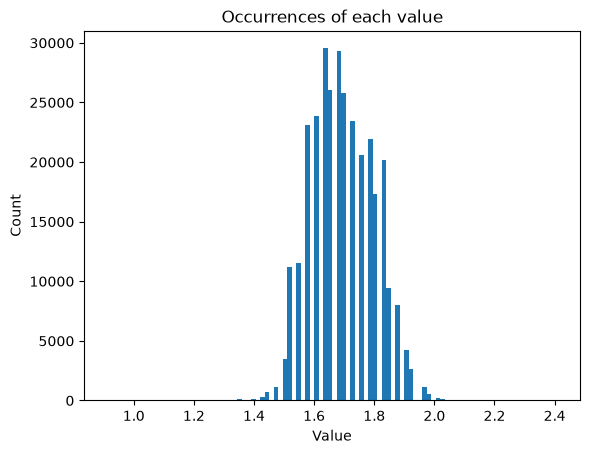

imputed and standardized data
missing data: 0 / 328135
possible values: [-7.42336101 -6.85570665 -6.57187947 -6.38266135 -6.28805229 -6.19344323
 -6.09883417 -6.00422511 -5.90961605 -5.81500698 -5.62578886 -5.24735262
 -5.15274356 -4.96352544 -4.86891638 -4.77430732 -4.67969826 -4.49048014
 -4.30126202 -4.20665296 -4.01743484 -3.82821672 -3.73360766 -3.54438954
 -3.35517142 -3.26056236 -3.07134424 -2.97673518 -2.78751705 -2.59829893
 -2.50368987 -2.40908081 -2.31447175 -2.21986269 -2.12525363 -2.03064457
 -1.93603551 -1.84142645 -1.74681739 -1.65220833 -1.55759927 -1.46299021
 -1.36838115 -1.27377209 -1.17916303 -1.08455397 -0.98994491 -0.89533585
 -0.80072679 -0.70611773 -0.61150867 -0.51689961 -0.42229055 -0.32768149
 -0.23307243 -0.13846337 -0.04385431  0.05075475  0.14536381  0.23997287
  0.33458194  0.429191    0.52380006  0.61840912  0.71301818  0.80762724
  0.9022363   0.99684536  1.09145442  1.18606348  1.28067254  1.3752816
  1.46989066  1.56449972  1.65910878  1.75371784  1.8

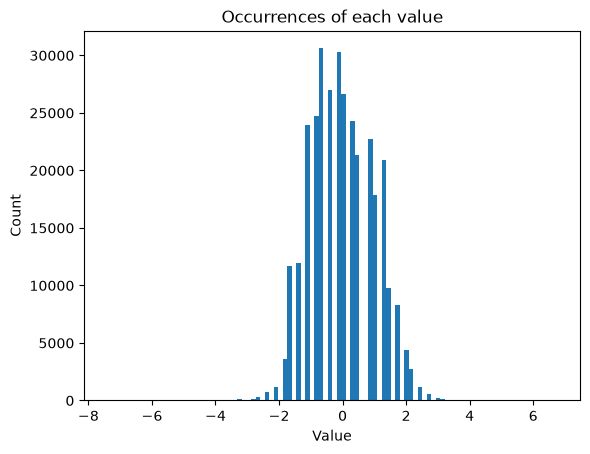

In [91]:
feat_raw = x_train_raw[:, idx]

plot_feature_distribution(feat_raw, "raw unprocessed data", True)
plot_feature_distribution(data, "imputed and standardized data", True)

In [ ]:
# impute data
"""
for idx in range(len(header)):

    data_type = FEATURE_INFO[header[idx]]["data_type"]
   
    if data_type == "binary":
        x_train[:, idx], param = fi.impute_mode(header[idx], x_train[:, idx], True)
        x_test[:, idx], _ = fi.impute_mode(header[idx], x_test[:, idx], True, param)
    elif data_type == "categorical":
        x_train[:, idx], param = fi.impute_mode(header[idx], x_train[:, idx], True)
        x_test[:, idx], _ = fi.impute_mode(header[idx], x_test[:, idx], True, param)
    elif data_type == "ordinal":
        x_train[:, idx], param = fi.impute_mode(header[idx], x_train[:, idx], True)
        x_test[:, idx], _ = fi.impute_mode(header[idx], x_test[:, idx], True, param)
    elif data_type == "discrete":
        x_train[:, idx], param = fi.impute_mode(header[idx], x_train[:, idx], True)
        x_test[:, idx], _ = fi.impute_mode(header[idx], x_test[:, idx], True, param)
    elif data_type == "continuous":
        x_train[:, idx], param = fi.impute_mode(header[idx], x_train[:, idx], True)
        x_test[:, idx], _ = fi.impute_mode(header[idx], x_test[:, idx], True, param)

"""

NameError: name 'header' is not defined